In [1]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import pickle
from PIL import Image
from pathlib import Path

## PP-RAI 2026

In [2]:
folsom_img_path = './data/folsom_20160308_103000.jpg'
alpnach_img_path = './data/alpnach_20180626_120000.png'
neuchatel_img_path = './data/ne_20180201_140000.png'
bern_img_path = './data/bern_20180308_120000.png'
karpicko_img_path = './data/karpicko_20250228_130000.jpg'
poznan_img_path = './data/poznan_20250410_150000.jpg'
modena_img_path = './data/modena_20260220.jpg'

def load_image(image_path):
    img = Image.open(image_path)
    img_array = np.array(img)
    return img_array

img_folsom = load_image(folsom_img_path)
img_alpnach = load_image(alpnach_img_path)
img_neuchatel = load_image(neuchatel_img_path)
img_bern = load_image(bern_img_path)
img_karpicko = load_image(karpicko_img_path)
img_poznan = load_image(poznan_img_path)
img_modena = load_image(modena_img_path)

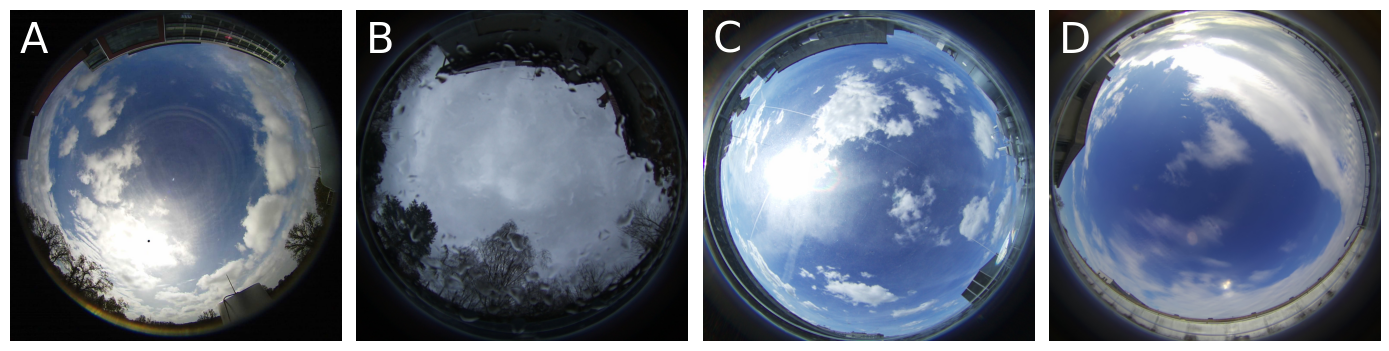

In [3]:
fig, ax = plt.subplots(1, 4, figsize=(14, 4))

ax[0].imshow(img_folsom)
# ax[0][1].imshow(img_alpnach)
# ax[0][2].imshow(img_neuchatel)
# ax[1][0].imshow(img_bern)
ax[1].imshow(img_karpicko[:, 254:-254])
ax[2].imshow(img_poznan[:, 254:-254])
ax[3].imshow(cv2.resize(img_modena[:, 206:-207], (img_folsom.shape[1], img_folsom.shape[0]), interpolation=cv2.INTER_AREA))

for _ax in ax.flatten():
    _ax.axis('off')
    # set A, B, C, ... labels
    _ax.text(0.03, 0.97, chr(ord('A') + ax.flatten().tolist().index(_ax)), transform=_ax.transAxes, color='white', fontsize=30, va='top')

plt.tight_layout()
# plt.savefig('sky_images.pdf', transparent=False, bbox_inches='tight')

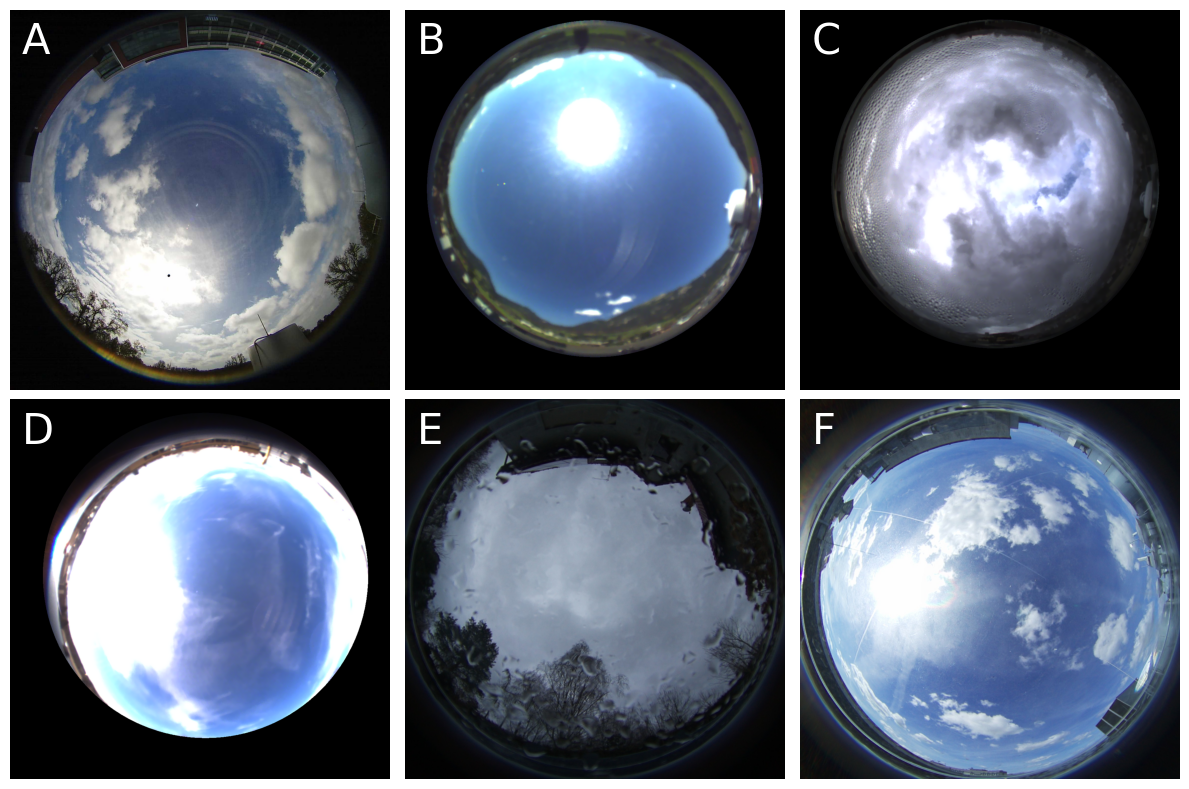

In [4]:
fig, ax = plt.subplots(2, 3, figsize=(12, 8))

ax[0][0].imshow(img_folsom)
ax[0][1].imshow(img_alpnach)
ax[0][2].imshow(img_neuchatel)
ax[1][0].imshow(img_bern)
ax[1][1].imshow(img_karpicko[:, 254:-254])
ax[1][2].imshow(img_poznan[:, 254:-254])

for _ax in ax.flatten():
    _ax.axis('off')
    # set A, B, C, ... labels
    _ax.text(0.03, 0.97, chr(ord('A') + ax.flatten().tolist().index(_ax)), transform=_ax.transAxes, color='white', fontsize=30, va='top')

plt.tight_layout()
# plt.savefig('sky_images.pdf', transparent=True)

In [6]:
periods_path = Path('../data/modena_prepared/modena_periods_4_5_15.pkl')

with open(periods_path, 'rb') as f:
    periods = pickle.load(f)

target_irradiances = np.stack([p['target_irradiance'] for p in periods])
offline_outputs = np.load(f'{str(periods_path.parent / periods_path.stem)}_raw_output.npy')
tta_outputs = np.load(f'{str(periods_path.parent / periods_path.stem)}_tta_output.npy')
tta_updates = np.load(f'{str(periods_path.parent / periods_path.stem)}_tta_updates.npy')

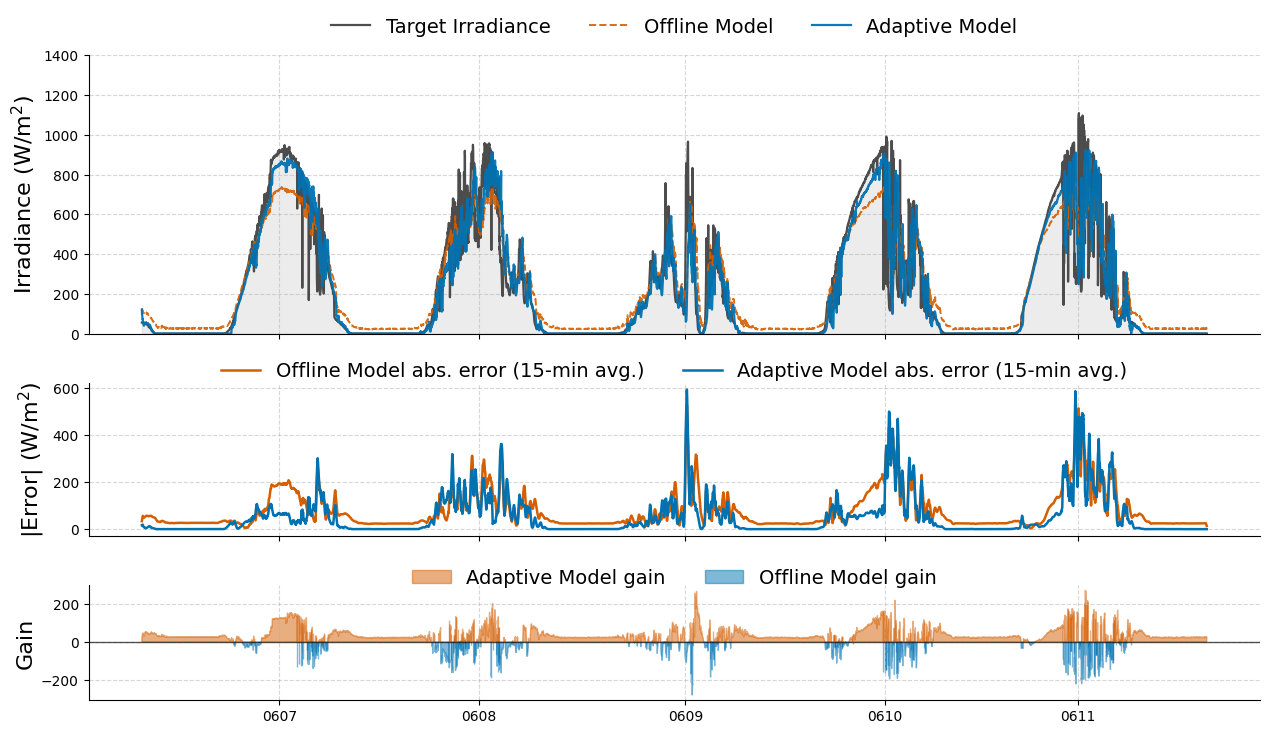

In [67]:
import matplotlib.pyplot as plt
import numpy as np

# Keep all series aligned to a common length
n = min(len(target_irradiances), len(offline_outputs), len(tta_outputs)) - 28 * 60
x = np.arange(n)
target = target_irradiances[:n]
offline = offline_outputs[:n]
adaptive = tta_outputs[:n]

# Error terms
offline_abs_err = np.abs(offline - target)
adaptive_abs_err = np.abs(adaptive - target)

# Positive values mean adaptive is better (lower absolute error)
adaptive_gain = offline_abs_err - adaptive_abs_err

# Smooth error curves for readability (about 15-minute window at 1-min sampling)
window = 15
kernel = np.ones(window) / window
offline_abs_err_smooth = np.convolve(offline_abs_err, kernel, mode="same")
adaptive_abs_err_smooth = np.convolve(adaptive_abs_err, kernel, mode="same")

# Colorblind-safe, high-contrast palette (Okabe-Ito inspired)
C_TARGET = "#3B3B3B"
C_OFFLINE = "#D55E00"
C_ADAPTIVE = "#0072B2"
C_GAIN_POS = "#009E73"
C_GAIN_NEG = "#CC79A7"

fig, (ax_main, ax_err, ax_gain) = plt.subplots(
    3, 1, figsize=(12.8, 7.4), sharex=True,
    gridspec_kw={"height_ratios": [2.9, 1.6, 1.2]}
)

# Panel 1: irradiance trajectory (cleaner than 3 heavy overlapping lines)
ax_main.fill_between(x, 0, target, color="#BDBDBD", alpha=0.28)
ax_main.plot(x, target, color=C_TARGET, lw=1.6, alpha=0.9, label="Target Irradiance")
ax_main.plot(x, offline, color=C_OFFLINE, lw=1.4, ls="--", alpha=0.9, label="Offline Model")
ax_main.plot(x, adaptive, color=C_ADAPTIVE, lw=1.6, alpha=0.95, label="Adaptive Model")
ax_main.set_ylabel("Irradiance (W/m$^2$)", fontsize=16)
ax_main.set_ylim(0, 1400)
ax_main.grid(axis="both", linestyle="--", alpha=0.5)
ax_main.legend(loc="upper center", ncol=4, frameon=False, fontsize=14, bbox_to_anchor=(0.5, 1.20))

# Panel 2: rolling absolute error comparison
ax_err.plot(x, offline_abs_err_smooth, color=C_OFFLINE, lw=1.8, label=f"Offline Model abs. error ({window}-min avg.)")
ax_err.plot(x, adaptive_abs_err_smooth, color=C_ADAPTIVE, lw=1.8, label=f"Adaptive Model abs. error ({window}-min avg.)")
ax_err.set_ylabel("|Error| (W/m$^2$)", fontsize=16)
ax_err.grid(axis="both", linestyle="--", alpha=0.5)
ax_err.legend(loc="upper center", ncol=2, frameon=False, fontsize=14, bbox_to_anchor=(0.5, 1.25))

# Panel 3: adaptive gain over offline
ax_gain.axhline(0, color="black", lw=1.0, alpha=0.65)
ax_gain.fill_between(x, 0, adaptive_gain, where=adaptive_gain >= 0, color=C_OFFLINE, alpha=0.5, label="Adaptive Model gain")
ax_gain.fill_between(x, 0, adaptive_gain, where=adaptive_gain < 0, color=C_ADAPTIVE, alpha=0.5, label="Offline Model gain")
ax_gain.set_ylabel("Gain", fontsize=16)
ax_gain.grid(axis="both", linestyle="--", alpha=0.5)
ax_gain.legend(loc="upper center", ncol=2, frameon=False, fontsize=14, bbox_to_anchor=(0.5, 1.30))

# Clean frame
for _ax in (ax_main, ax_err, ax_gain):
    _ax.spines["top"].set_visible(False)
    _ax.spines["right"].set_visible(False)

if periods_path.parent.name == "modena_prepared":
    xticks = [1000, 2450, 3950, 5400, 6800]
    xlabels = ["0607", "0608", "0609", "0610", "0611"]
    ax_gain.set_xticks(xticks)
    ax_gain.set_xticklabels(xlabels)
else:
    raise ValueError("Unknown dataset")

plt.tight_layout()
plt.savefig(f"irradiance_representation_{periods_path.parent.name.lower()}.pdf", transparent=False, bbox_inches="tight")